<a href="https://colab.research.google.com/github/thikraedies-create/EDA/blob/main/Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

أول كود عندي هو كود تجهيز بيئة العمل

 البداية فعلت عرض الرسومات داخل الـ Notebook وبعدها استوردت المكتبات التي رح أحتاجها  

استخدمت مكتبة Pandas للتعامل مع البيانات والجداول واستخدمت NumPy للعمليات العددية أما Matplotlib و Seaborn فاستوردتهم لإنشاء الرسومات البيانية والإحصائية

كمان استوردت أدوات من Scikit-learn لتحويل البيانات النصية إلى أرقام وتوحيد مقاييس المتغيرات العددية واختيار أفضل الخصائص بناء على اختبار إحصائي

بعد هيك ضبطت شكل الرسومات وطريقة عرض الجداول حتى تكون النتائج أوضح وأسهل في القراءة

وفي النهاية طبعت رسالة تؤكد أن الكود وصل إلى نهايته بنجاح

In [28]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (15, 5)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

print("All packages loaded successfully.")


All packages loaded successfully.


هذا الكود استخدمته حتى أتأكد من مسار العمل الحالي في بايثون وأعرف الملفات الموجودة داخله لأن المشروع بيعتمد على قراءة ملف البيانات ولازم أتأكد إن ملف البيانات موجود في المكان الصحيح حتى أقدر أستخدمه في خطوات التحليل القادمة

In [29]:
import os
print(os.getcwd())
print(os.listdir())

/content
['.config', 'german_credit_data - german_credit_data (1).csv', 'sample_data']


في هذا الكود حددت اسم ملف البيانات الذي رح أستخدمه   وبعدها قرأت الملف باستخدام مكتبة Pandas وخزنت البيانات داخل متغير اسمه Datasetحتى أقدر أعمل عليها التحليل بعدين وفي النهاية طبعت عدد الصفوف والأعمدةا

In [30]:
DATA_PATH = "german_credit_data - german_credit_data (1).csv"

dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")


Dataset loaded: 1000 rows, 10 columns


في هذا الكود استخدمت الدالة head() حتى أعرض أول خمس صفوف من البيانات وأتعرف على شكل الجدول وأسماء الأعمدة والقيم الموجودة فيه وهذا بساعدني أفهم طبيعة البيانات قبل ما أبدأ بعملية التحليل
رح يظهر جدول يحتوي على أول خمس سجلات من ملف البيانات مع أسماء الأعمدة والقيم الموجودة تحت كل عمود

مثلا ممكن تظهر أعمدة مثل العمر والجنس والمبلغ الائتماني  حسب الأعمدة الموجودة فعليا

In [31]:
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


في هذا الكود استخدمت dataset.shape حتى أعرف حجم مجموعة البيانات من حيث عدد الصفوف والأعمدة وهذا بساعدني آخذ فكرة عامة عن حجم البيانات اللي رح أشتغل عليها وأتأكد من عدد السجلات والمتغيرات الموجودة فيها

In [32]:
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


في هذا الكود استخدمت dataset.dtypes حتى أعرف نوع البيانات في كل عمود وأحدد إذا كانت القيم أرقاما أو نصوصا وهذا مهم لأنني لازم أفهم  

طبيعة البيانات قبل ما أبدأ بتنظيفها وتجهيزها للتحليل أو لتطبيق نماذج تعلم الآلة
رح يظهر اسم كل عمود وبجانبه نوع البيانات الخاصة في

In [33]:
dataset.dtypes

,0
Age,int64
Sex,object
Job,int64
Housing,object
SavingAccounts,object
CheckingAccount,object
CreditAmount,int64
Duration,int64
Purpose,object
Risk,object


في هذا الكود استخدمت describe() حتى أحصل على ملخص إحصائي للأعمدة الرقمية في البيانات ومن خلاله بقدر أعرف عدد القيم والمتوسط وأصغر وأكبر قيمة ومدى انتشار البيانات وهذا بساعدني أفهم خصائص البيانات وألاحظ إذا في قيم ممكن تحتاج إلى مراجعة خلال مرحلة التحليل

In [34]:
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


في هذا الكود استخدمت describe() مع exclude="number" حتى أستبعد الأعمدة الرقمية وأركز على الأعمدة غير الرقمية مثل البيانات النصية والتصنيفية ومن خلال النتيجة بقدر أعرف عدد القيم الموجودة وعدد القيم المختلفة وأكثر قيمة متكررة وعدد مرات تكرارها وهذا بساعدني أفهم طبيعة البيانات غير الرقمية قبل ما أكمل التحليل

In [35]:
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


في هذا الكود بفحص مجموعة البيانات حتى أعرف إذا في قيم مفقودة في أي عمود وبستخدم isna() لتحديد الخلايا الفارغة و sum() لحساب عددها في كل عمود وبعدها بطبع النتيجة حتى أعرف إذا كانت البيانات بحاجة إلى معالجة القيم المفقودة قبل ما أكمل التحليل
ظهر الرقم صفر أمام أحد الأعمدة فهذا يعني أنه لا يحتوي على قيم مفقودة يتعرف عليها Pandas وهذا لا يعني بالضرورة أن كل بيانات العمود صحيحة أو مكتملة من جميع النواحي

In [36]:
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


في هذا الكود حللت توزيع الفئات الموجودة في عمود Risk حتى أعرف عدد الحالات في كل فئة أولا ثم حسبت النسبة المئوية لكل فئة من إجمالي البيانات وهذا بساعدني أفهم توزيع المخاطر وأعرف إذا كانت إحدى الفئات ممثلة في البيانات أكثر من الفئة الثانية
استخدمت value_counts() حتى أحسب عدد مرات ظهور كل فئة في عمود Risk والذي يمثل مستوى المخاطر في البيانات ثم طبعت النتيجة حتى أعرف عدد الحالات الموجودة في كل فئة
حسبت النسبة لكل فئة من إجمالي البيانات باستخدام normalize=True وبعدها استخدمت round(3) لتقريب النسب إلى ثلاث خانات عشرية ثم ضربت الناتج في 100 لتحويله إلى نسبة مئوية وأخيرا طبعت النسب مع عبارة توضح أنها نسبة من إجمالي البيانات

In [37]:
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


في هذا الكود استوردت مكتبة Matplotlib وتحديدا الجزء pyplot واختصرت اسمه إلى plt حتى أستخدمه في إنشاء الرسومات البيانية التي بتساعدني أعرض البيانات وأفهمها بشكل أوضح خلال التحليل

In [38]:
import matplotlib.pyplot as plt

في هذا الكود بدأت بحساب عدد القيم المفقودة في كل عمود وبعدها استبعدت الأعمدة التي لا تحتوي على قيم مفقودة ورتبت الأعمدة المتبقية من الأكثر فقدا إلى الأقل ثم أنشأت رسما بيانيا بالأعمدة حتى أقدر أشوف توزيع القيم المفقودة بشكل واضح وهذا بساعدني أحدد إذا في أعمدة تحتاج إلى معالجة قبل ما أكمل تحليل البيانات
هذا الكود يكتشف القيم المفقودة ويعرضها بصريا لكنه لا يحذفها ولا يعالجها وإنما يساعدني على فهم حجم المشكلة قبل اتخاذ قرار بشأنها

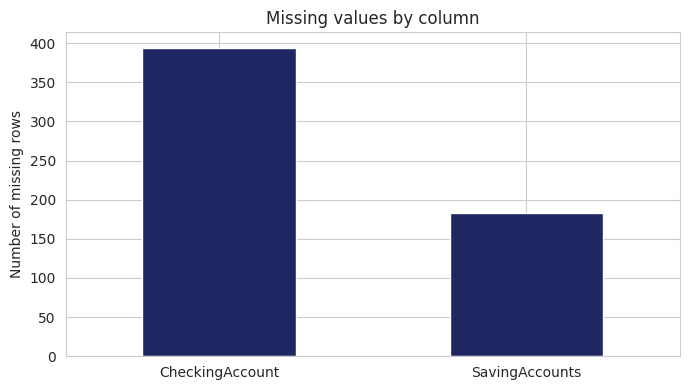

In [39]:
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#1E2761")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

في هذا الكود اخترت أربعة متغيرات رقمية من مجموعة البيانات ورسمت لكل متغير مدرجا تكراريا باستخدام Pandas و Matplotlib وقسمت القيم إلى 20 فئة حتى أشوف كيف تتوزع البيانات وأعرف أين تتركز معظم القيم وهل التوزيع متقارب أو فيه قيم مرتفعة أو منخفضة بشكل ملحوظ وهذا بساعدني أفهم طبيعة المتغيرات قبل الانتقال إلى خطوات التحليل التالية

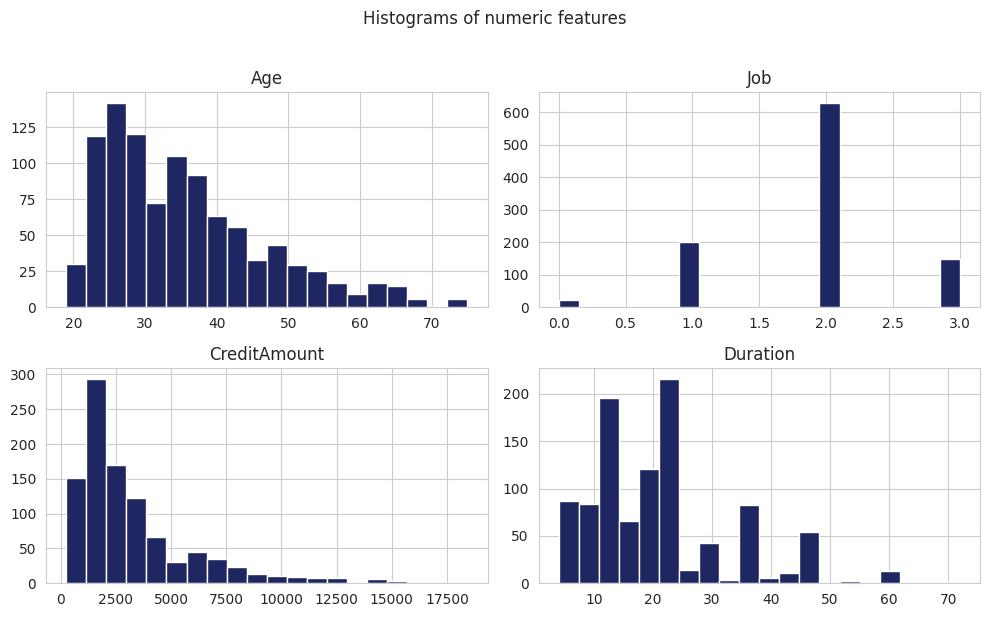

In [40]:
#HISTOGRAM for the numeric coulumns:

numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(
    figsize=(10, 6),
    bins=20,
    color="#1E2761",
    edgecolor="white"
)

plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()

في هذا الكود استخدمت مخططات الصندوق لفحص المتغيرات الرقمية واكتشاف القيم المتطرفة المحتملة ورسمت مخططا لكل متغير حتى أقدر أقارن توزيع القيم بينها وألاحظ إذا في قيم بعيدة عن معظم البيانات وهذا بساعدني أفهم البيانات وأحدد إذا كانت بعض القيم تحتاج إلى مراجعة قبل متابعة التحليل
ظهور قيمة متطرفة لا يعني بالضرورة أنها خطأ أو لازم نحذفها فقد تكون قيمة صحيحة فعليا لذلك هذا الكود هدفه اكتشاف القيم التي تستحق الفحص وليس حذفها أو تعديلها تلقائيا

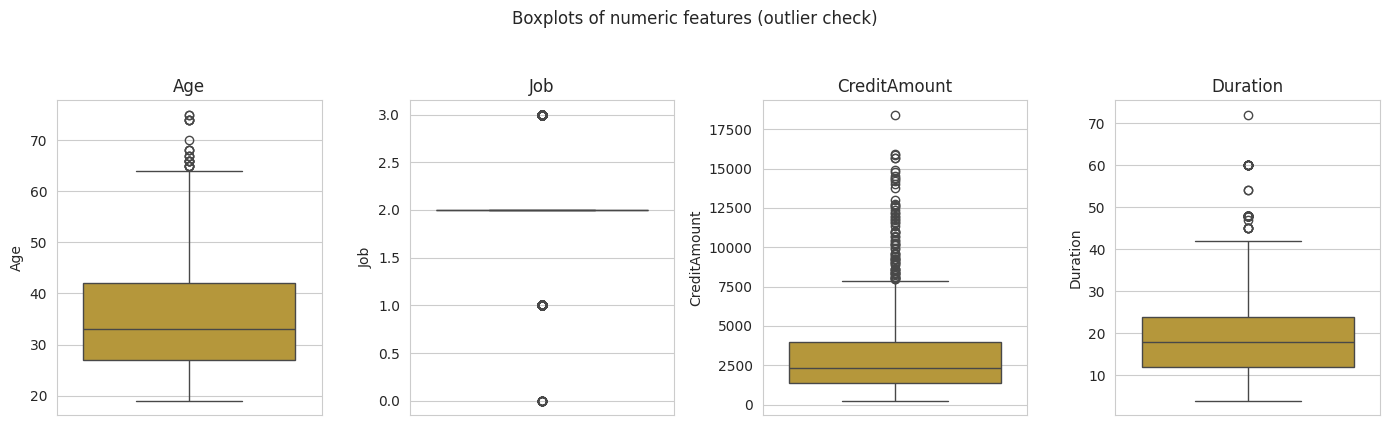

In [41]:
# Boxplots are a fast way to spot outliers: the box shows the middle 50% of
# values, the whiskers show the typical range, and dots beyond that are outliers.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()

# Interpretation: CreditAmount and Duration both show a right-skewed distribution
# with several high-value outliers -- large loans are less common but do occur.

استخدمت هذا الكود لتحليل المتغيرات التصنيفية في مجموعة البيانات من خلال إنشاء ستة مخططات بالأعمدة توضح عدد السجلات في كل فئة واستبدلت القيم المفقودة بكلمة Missing حتى تظهر في الرسم كفئة مستقلة ثم رتبت الفئات من الأكثر تكرارا إلى الأقل تكرارا حتى تكون المقارنة أسهل ومن خلال هذه الرسومات بقدر أفهم توزيع البيانات وأعرف الفئات الأكثر والأقل ظهورا وألاحظ كيف تتوزع فئات المخاطر في مجموعة البيانات

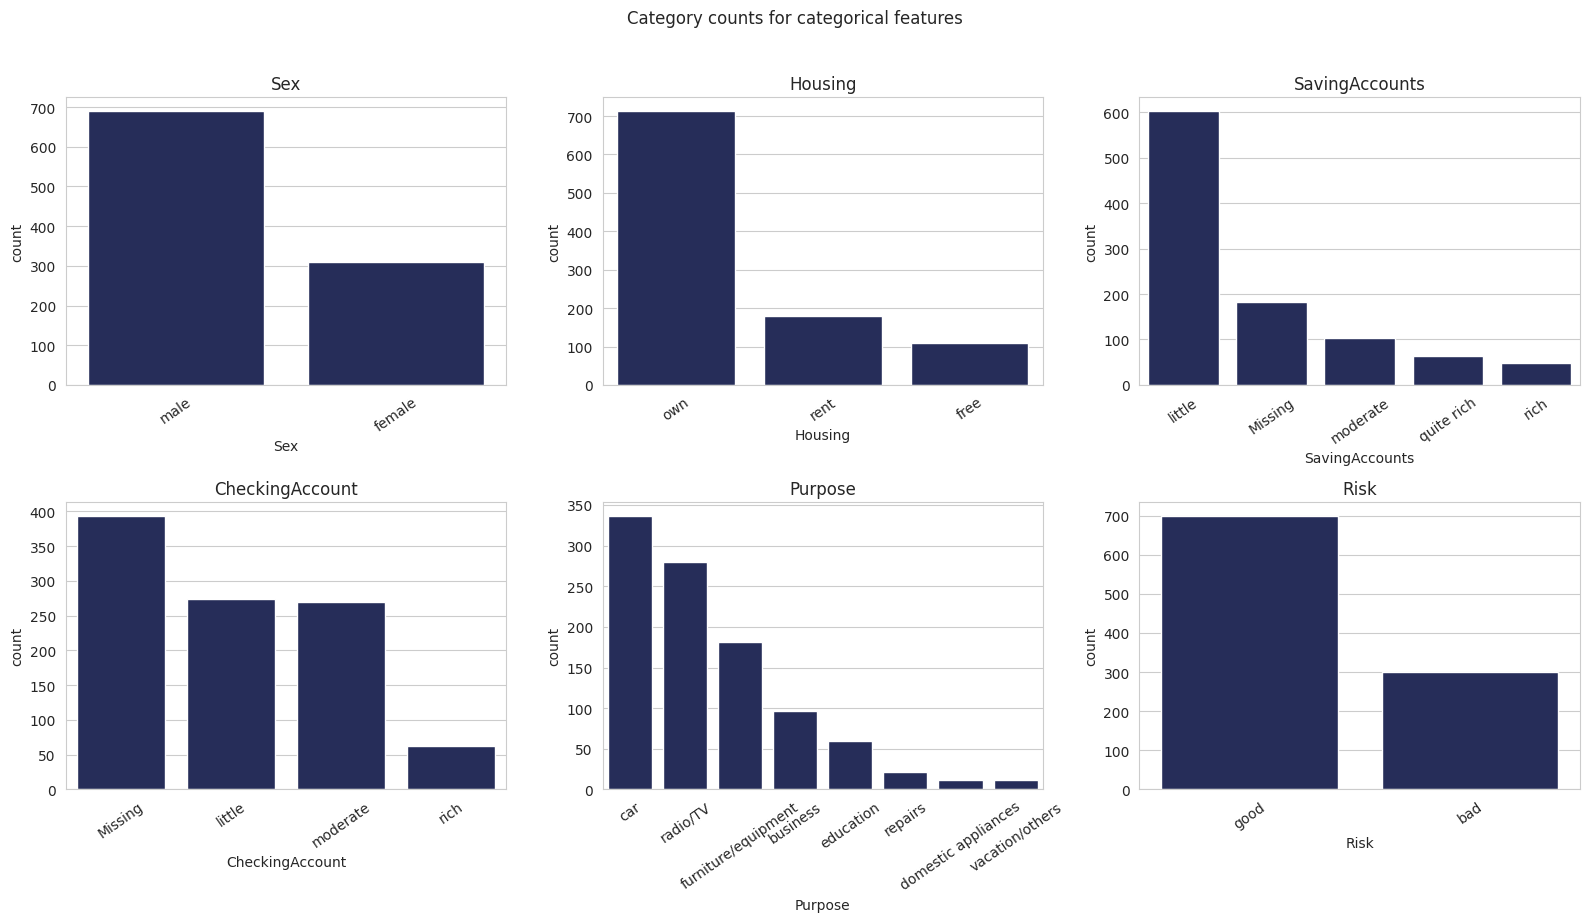

In [42]:
# Count plots for the categorical columns: how many rows fall into each category?
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    # Fill missing values with the string "Missing" so they show up as their own
    # bar instead of being silently dropped by the plotting library.
    col_data = dataset[col].fillna("Missing")

    # order=... sorts bars from most to least common, which is easier to read
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)

plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()

بهذا الجزء من الكود انا بعمل خريطة الارتباط الحرارية والهدف منها اني اعرف قوة واتجاه العلاقة بين المتغيرات الرقمية الموجودة في البيانات

اول اشي بحدد حجم الرسم باستخدام plt.figure وبعدها بحسب معاملات الارتباط بين الاعمدة الرقمية باستخدام dataset[numeric_cols].corr() وبخزن النتائج في متغير اسمه correlation

بعد هيك بستخدم sns.heatmap() عشان اعرض نتائج الارتباط على شكل مربعات ملونة وبخلي مقياس الالوان يبدأ من سالب واحد وينتهي عند موجب واحد وبستخدم annot=True عشان تظهر قيمة الارتباط داخل كل مربع وبستخدم cmap="vlag" لتحديد الالوان و square=True عشان تكون المربعات مربعة الشكل

بعدين بضيف عنوان للرسم باستخدام plt.title() وبرتب المسافات باستخدام plt.tight_layout() وبالاخر بعرض الرسم باستخدام plt.show()

من خلال الرسم بقدر اعرف اذا العلاقة بين متغيرين طردية او عكسية واذا كانت قوية او ضعيفة ولازم انتبه انه الارتباط مش بالضرورة يعني انه متغير هو السبب في تغير المتغير الثاني

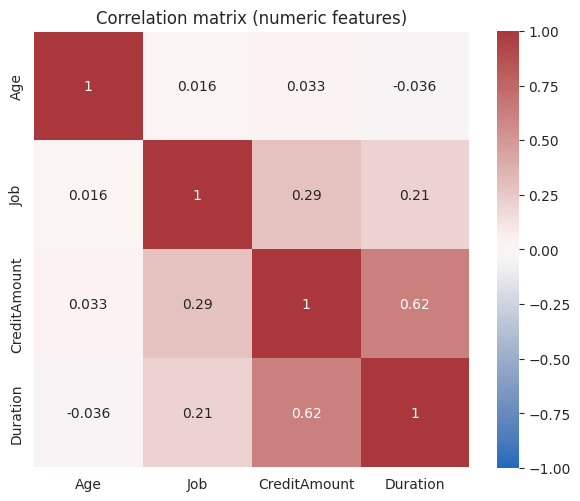

In [43]:
# Correlation heatmap: how strongly are the NUMERIC features related to each other?
# Values close to +1 or -1 mean two features move together strongly;
# values near 0 mean little to no linear relationship.

plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

بهذا الجزء من الكود انا بعمل رسم اسمه Pairplot والهدف منه اني اشوف العلاقة بين المتغيرات الرقمية وكيف بتختلف بين الحالات الجيدة والسيئة من ناحية المخاطر

بستخدم sns.pairplot() حتى ارسم العلاقة بين كل متغير والمتغيرات الثانية وبحدد الاعمدة الرقمية باستخدام vars=numeric_cols

اما hue="Risk" فبميز الحالات حسب نوع المخاطر بألوان مختلفة و palette بتحدد الالوان المستخدمة لكل نوع

وبستخدم diag_kind="hist" حتى اعرض توزيع كل متغير على شكل مدرج تكراري

بعدها بستخدم plt.suptitle() حتى اضيف عنوان للرسم وبالاخر plt.show() حتى اعرضه على الشاشة

من خلال الرسم بقدر الاحظ اذا في اختلافات او انماط بين الحالات الجيدة والسيئة من ناحية العمر ومبلغ القرض ومدة القرض

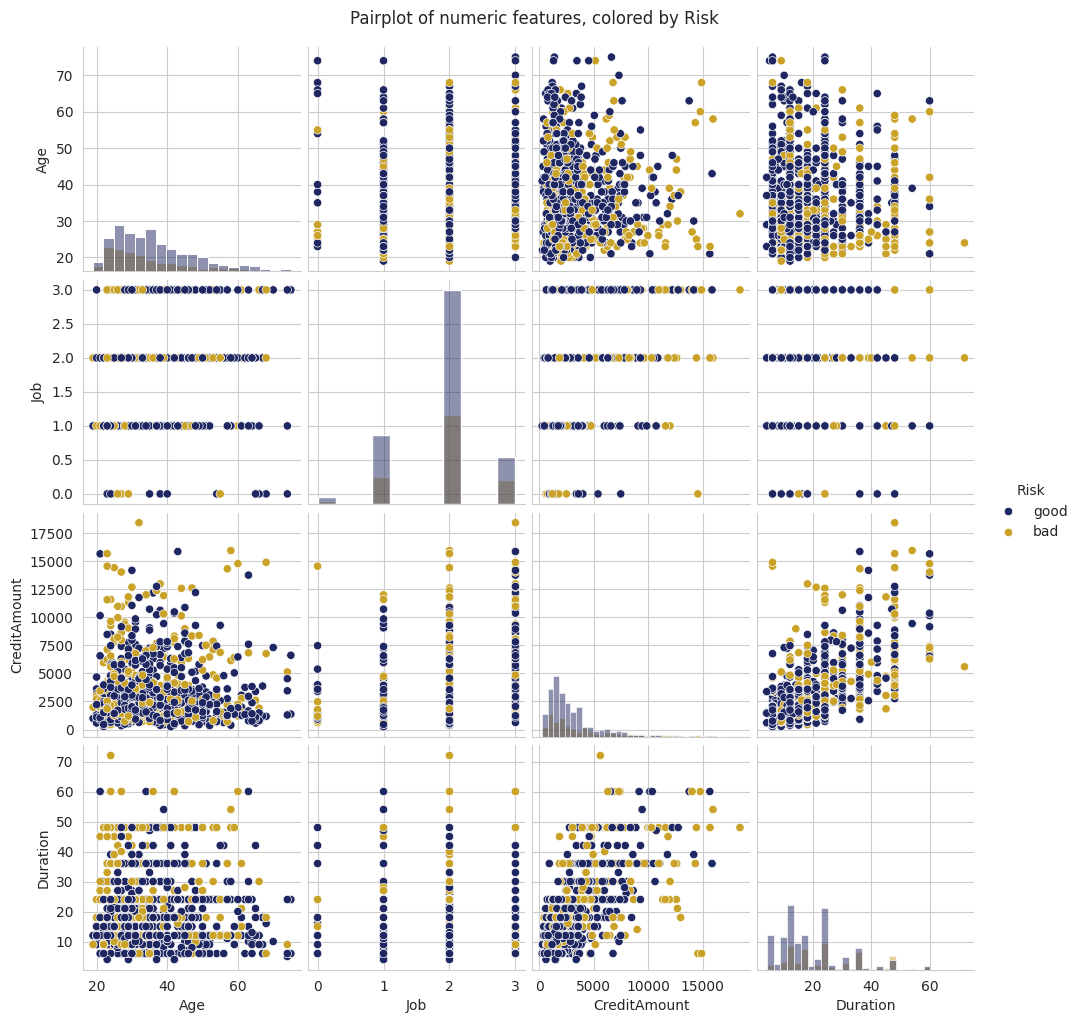

In [44]:
# A pairplot ("scatterplot matrix") plots every numeric feature against every
# other one, colored by Risk -- a fast way to see whether good/bad risk cases
# separate visually along any pair of features.

sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

بهذا الجزء من الكود انا بعمل رسومات Boxplot عشان اقارن توزيع المتغيرات الرقمية بين الاشخاص اللي عندهم مخاطر ائتمانية جيدة والاشخاص اللي عندهم مخاطر سيئة

اول اشي بستخدم plt.subplots() عشان انشئ عدة رسومات بنفس الشكل بحيث يكون لكل متغير رسم خاص فيه

بعدها بستخدم for loop عشان امر على كل متغير رقمي وبستخدم sns.boxplot() عشان ارسم توزيع المتغير حسب نوع المخاطر

المتغير x="Risk" بحدد نوع المخاطر والمحور y بعرض قيم المتغير الرقمي اما hue="Risk" والالوان فبساعدوني اميز بين الحالات الجيدة والسيئة

وبستخدم ax.set_title() عشان احط عنوان لكل رسم حسب اسم المتغير

وبالاخر plt.tight_layout() عشان ارتب المسافات بين الرسومات و plt.show() عشان اعرضهم على الشاشة

من خلال الرسومات بقدر اقارن بين الحالات الجيدة والسيئة واشوف اذا في اختلاف في توزيع العمر او مبلغ القرض او مدة القرض وهذا ممكن يساعدنا نعرف اي متغيرات ممكن تكون مفيدة في تحليل المخاطر الائتمانية

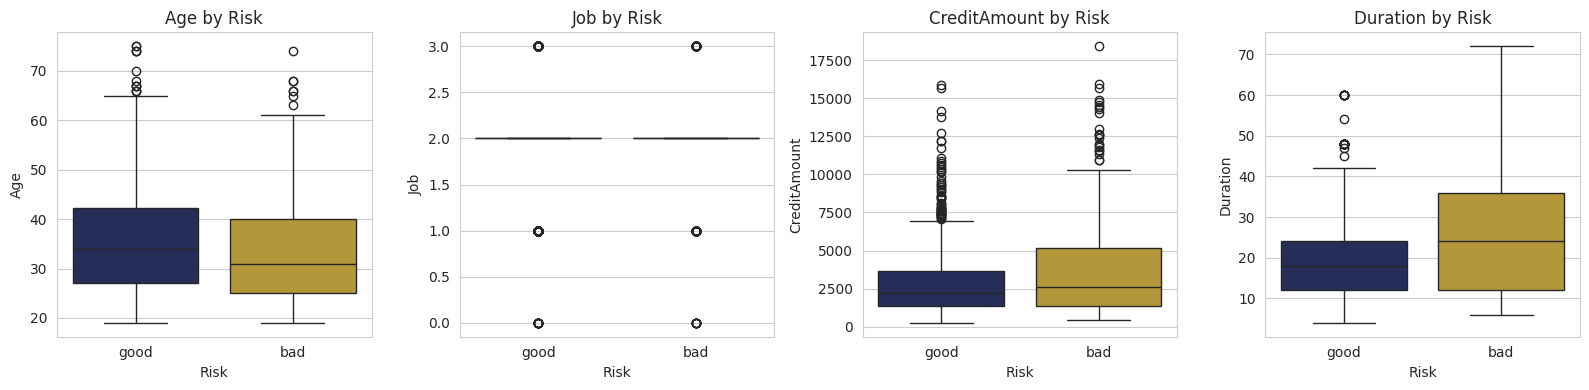

In [45]:
# Boxplots grouped by Risk: does the DISTRIBUTION of a numeric feature look
# different for 'good' vs 'bad' risk applicants? A visible difference suggests
# that feature could be informative for a future model.

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=dataset,
        x="Risk",
        y=col,
        hue="Risk",
        palette={"good": "#1E2761", "bad": "#C9A227"},
        legend=False,
        ax=ax
    )
    ax.set_title(f"{col} by Risk")

plt.tight_layout()
plt.show()

# Interpretation: 'bad' risk applicants tend to have somewhat higher CreditAmount
# and Duration -- larger, longer loans look riskier, which matches financial
# intuition

بهذا الجزء من الكود انا بعمل تنظيف للبيانات وبعالج القيم المفقودة الموجودة في الجدول

اول اشي بستخدم dataset.copy() عشان اعمل نسخة من البيانات الاصلية بدون ما اغير عليها

بعدها بستخدم fillna("none") عشان اعوض القيم المفقودة في عمود SavingAccounts وعمود CheckingAccount بكلمة none بدل ما احذف الصفوف من البيانات

وبالاخر بستخدم isna().sum() عشان اتأكد اذا ضل في قيم مفقودة في الاعمدة واذا كانت النتيجة صفر معناها انه ما ضل قيم مفقودة في البيانات بعد عملية التنظيف

In [46]:
# Work on a copy so the original raw dataset stays untouched for reference.
df_clean = dataset.copy()

# Fill missing values with an explicit "none" category (domain-informed choice --
# see markdown above). This keeps every row usable instead of dropping ~40% of
# the data (394 rows are missing CheckingAccount alone).
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Double-check: there should be zero missing values left anywhere in the dataset.
print("Remaining missing values:\n")
print(df_clean.isna().sum())

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


هذا الجزء من الكود انا بحول البيانات النصية الى ارقام عشان تصير مناسبة للمعالجة والتحليل

اول اشي بعمل نسخة من البيانات النظيفة باستخدام df_clean.copy() وبخزنها في متغير اسمه df_encoded

بعدها بحدد الاعمدة النصية اللي بدي احولها لارقام مثل الجنس والسكن وحسابات التوفير والحساب الجاري والغرض من القرض ونوع المخاطر

بعدين بستخدم encoders عشان اخزن ادوات التحويل اللي رح استخدمها لكل عمود

داخل الحلقة for بمر على كل عمود وبستخدم LabelEncoder() لتحويل كل فئة نصية الى رقم وبخزن النتيجة داخل نفس العمود

وبستخدم fit_transform() عشان يتعلم الفئات الموجودة في العمود ويحولها الى ارقام

وبعدها بخزن اداة التحويل داخل encoders حتى اقدر ارجع اعرف كل رقم لاي فئة نصية برجع

وبالاخر print بعرض اسم كل عمود والفئات اللي تم تحويلها الى ارقام عشان اتأكد من عملية التحويل

In [47]:
# --- Encode categorical columns ---
# LabelEncoder assigns each category an integer code, e.g. 'good'/'bad' -> 1/0.
# (For features with no natural order, one-hot encoding is often preferred over
# label encoding before modeling -- we use LabelEncoder here purely to keep this
# preprocessing demo simple and inspectable.)

df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}  # keep the fitted encoders in case we need to decode values later

for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


لكود هون بعمل Scaling للبيانات الرقمية يعني بوحد مقياس الارقام عشان تصير مناسبة اكثر للاستخدام في نماذج تعلم الالة

بالبداية بنستخدم StandardScaler وهي اداة بتحول القيم بحيث يصير المتوسط الحسابي لكل عمود صفر تقريبا والانحراف المعياري واحد

بعدها بنحدد الاعمدة اللي بدنا نعمل الها Scaling وهي العمر والوظيفة ومبلغ الائتمان ومدة الائتمان

بعدين بنعمل نسخة من البيانات الاصلية باسم df_scaled عشان نحافظ على البيانات قبل التعديل وبنطبق عليها التحويل باستخدام fit_transform

بالنهاية بنطبع اول ثلاث صفوف قبل التحويل وبعده عشان نقارن التغير و round(3) بتقرب الارقام لثلاث خانات عشرية

In [48]:
# --- Scale numeric columns ---
# StandardScaler transforms each numeric column to have mean 0 and std dev 1.

scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# Compare a couple of rows before vs. after scaling, to see what changed.
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739



الكود هون بعرض رسمين بيانيين لمبلغ الائتمان قبل وبعد عملية Scaling عشان نشوف كيف تغيرت القيم

بالبداية بنعمل رسمين جنب بعض باستخدام plt.subplots وبعدها بنرسم توزيع قيم CreditAmount قبل التحويل باستخدام sns.histplot وبنرسم التوزيع نفسه بعد التحويل من df_scaled

الرسم الاول بوضح القيم الاصلية لمبلغ الائتمان والرسم الثاني بوضح القيم بعد ما توحد مقياسها باستخدام Scaling

بالنهاية بنستخدم plt.tight_layout لترتيب الرسومات و plt.show لعرضها

الفكرة من الكود انه عملية Scaling بتغير مقياس الارقام على المحور الافقي لكن شكل التوزيع بشكل عام بضل نفسه يعني بتتغير القيم ومداها لكن توزيع البيانات بضل مشابه

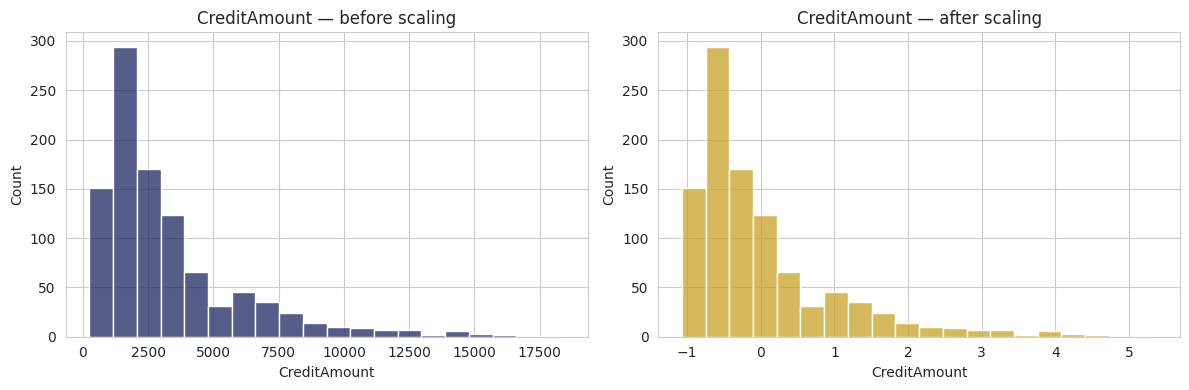

In [49]:
# Visual check: scaling changes the AXIS, not the SHAPE, of a distribution.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount — before scaling")

sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#C9A227")
axes[1].set_title("CreditAmount — after scaling")

plt.tight_layout()
plt.show()

الكود هون بفصل البيانات عن العمود اللي بدنا نتوقعه وهو Risk بحيث X بتحتوي على الخصائص والاعمدة اللي رح نستخدمها للتحليل و y بتحتوي على تصنيف المخاطر سواء good او bad

بعدها بنستخدم SelectKBest مع f_classif عشان نقيم كل عمود ونعرف قديش هو مرتبط بالاختلاف بين مجموعات المخاطر وكل ما كانت الدرجة اعلى كان العمود اكثر فائدة في التمييز بين المجموعتين

وبعدين بنجمع اسماء الاعمدة ودرجاتها في جدول اسمه feature_scores وبنرتب الجدول من اعلى درجة لاقل درجة عشان نعرف اي الخصائص اكثر اهمية في التمييز بين فئات Risk

استخدام k="all" يعني بنحسب درجة كل الاعمدة بدون ما نحذف اي عمود حاليا

In [50]:
# Separate the features (X) from the target-like column (y).
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# SelectKBest + f_classif scores every feature with an ANOVA F-test: a higher
# score means the feature's values differ more between the 'good' and 'bad'
# Risk groups -- i.e., it looks more informative.
selector = SelectKBest(score_func=f_classif, k="all")   # k="all" -> score every feature, keep none/drop none yet
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


الكود هون برسم مخطط اعمدة بوضح درجات الخصائص اللي حسبناها بالكود السابق وعلاقة كل خاصية بالعمود Risk

بنستخدم sns.barplot عشان نرسم الخصائص مقابل درجاتها وكل ما كان العمود اطول كانت الخاصية اكثر قدرة على التمييز بين مجموعات المخاطر حسب الاختبار الاحصائي المستخدم

بعدها بنضيف عنوان للرسم واسم للمحور الافقي اللي بوضح درجة F-score وبنرتب الرسم باستخدام tight_layout وبنعرضه باستخدام show

الفكرة المهمة انه الرسم بساعدنا نعرف اي الخصائص ممكن تكون اكثر فائدة لما نبدأ ببناء نموذج تعلم الالة لكنه مش نموذج مدرب وما بتنبأ بالمخاطر لحاله

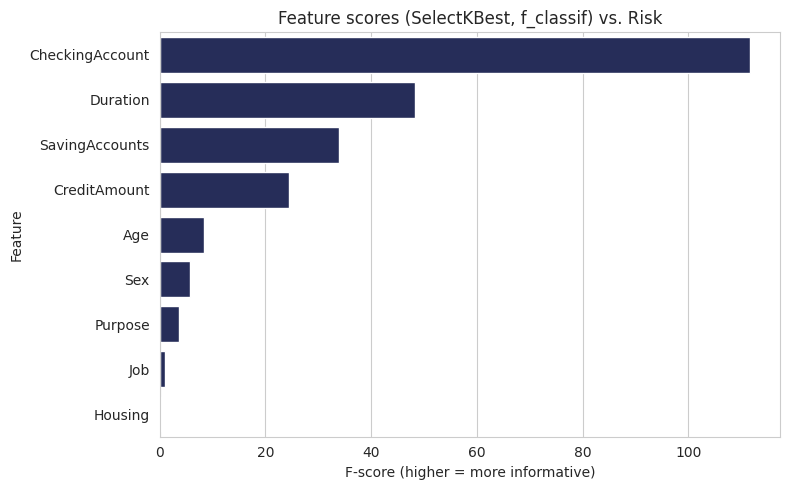

In [51]:
# Bar chart of feature scores -- the taller the bar, the more informative the
# feature looks with respect to Risk, based purely on this statistical test.

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#1E2761")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()

# Reminder: this ranking is a PREPROCESSING step, not a trained model. It helps
# guide which features to prioritize when modeling starts -- it does not predict
# anything by itself.